# 03 - Phases of play and venues
Ball-by-ball analysis (only matches that have it) and ground effects. Super Overs excluded.

In [1]:
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "warehouse" / "cricket_gold.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).fetchdf()
FMT = {"ODI": "#2a6fbb", "T20": "#e07b00"}   # one colour per format, used everywhere
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.figsize": (9, 4.2)})
pd.set_option("display.width", 160)

## Run rate and dot balls by phase

format     phase  run_rate  dot_pct  boundary_pct  wicket_pct  balls
   ODI powerplay      4.80    63.92         10.41        2.37  32894
   ODI    middle      5.05    50.92          7.93        2.24  88146
   ODI     death      7.39    37.56         12.93        5.70  20205
   T20 powerplay      7.30    47.67         16.63        4.63  17073
   T20    middle      7.40    32.77         11.71        4.60  24241
   T20     death      9.22    30.35         17.19        8.83  11178


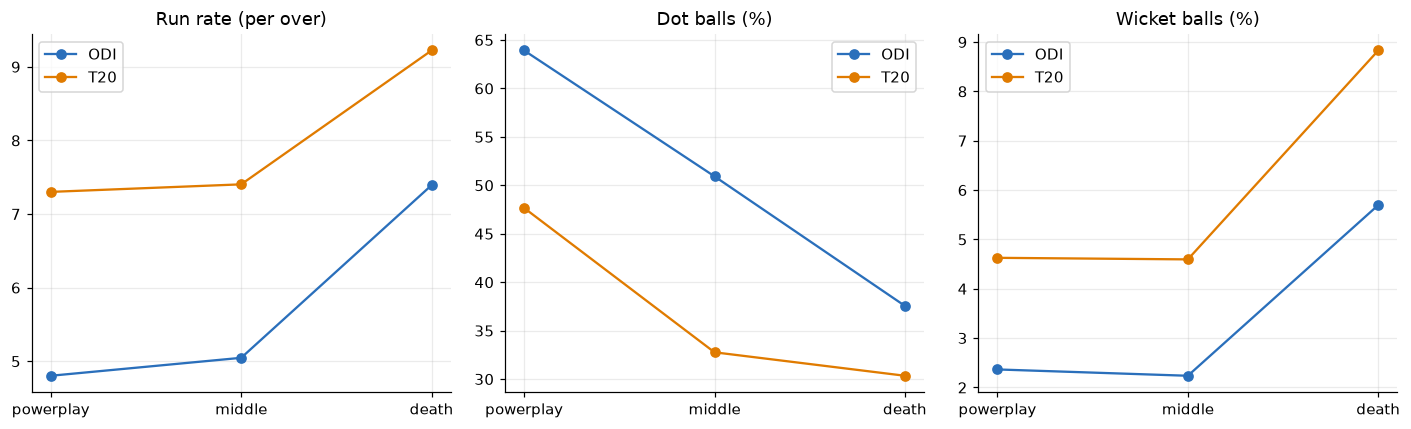

In [2]:
ph = q("""select format, phase, 6.0*sum(total_runs)/count(*) filter (where is_legal_ball) as run_rate,
  100.0*avg(case when is_dot_ball then 1.0 else 0 end) as dot_pct, 100.0*avg(case when is_boundary then 1.0 else 0 end) as boundary_pct,
  100.0*avg(case when is_wicket then 1.0 else 0 end) as wicket_pct, count(*) balls
  from gold.fact_deliveries where not is_super_over and phase in ('powerplay','middle','death') group by 1,2""")
order = {"powerplay": 0, "middle": 1, "death": 2}
ph = ph.sort_values(["format", "phase"], key=lambda s: s.map(order) if s.name == "phase" else s)
print(ph.round(2).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, ttl in zip(axes, ["run_rate", "dot_pct", "wicket_pct"], ["Run rate (per over)", "Dot balls (%)", "Wicket balls (%)"]):
    for f, g in ph.groupby("format"):
        ax.plot(g.phase, g[col], "o-", color=FMT[f], label=f)
    ax.set_title(ttl); ax.legend()
plt.tight_layout(); plt.show()

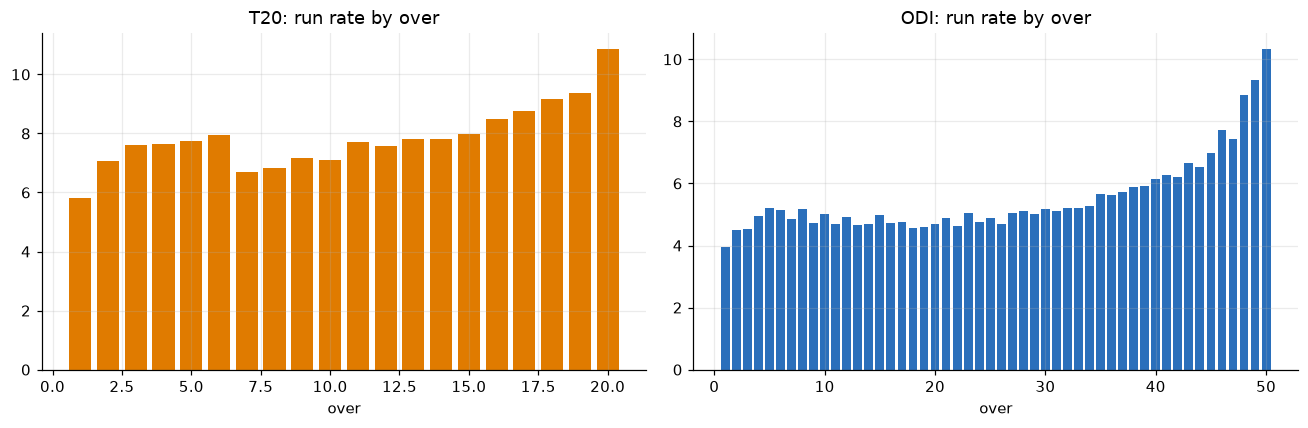

FINDING [T20]: fastest over on average is over 20 (10.9 rpo); slowest is over 1 (5.8 rpo)


In [3]:
ov = q("""select format, over_number, 6.0*sum(total_runs)/count(*) filter (where is_legal_ball) rr, 100.0*avg(case when is_wicket then 1.0 else 0 end)*6 wk_per_over
  from gold.fact_deliveries where not is_super_over and ((format='T20' and over_number<=20) or (format='ODI' and over_number<=50)) group by 1,2 order by 1,2""")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, f in zip(axes, ["T20", "ODI"]):
    g = ov[ov.format == f]; ax.bar(g.over_number, g.rr, color=FMT[f]); ax.set_title(f"{f}: run rate by over"); ax.set_xlabel("over")
plt.tight_layout(); plt.show()
t = ov[ov.format == "T20"].set_index("over_number").rr
print(f"FINDING [T20]: fastest over on average is over {t.idxmax()} ({t.max():.1f} rpo); slowest is over {t.idxmin()} ({t.min():.1f} rpo)")

## Venues

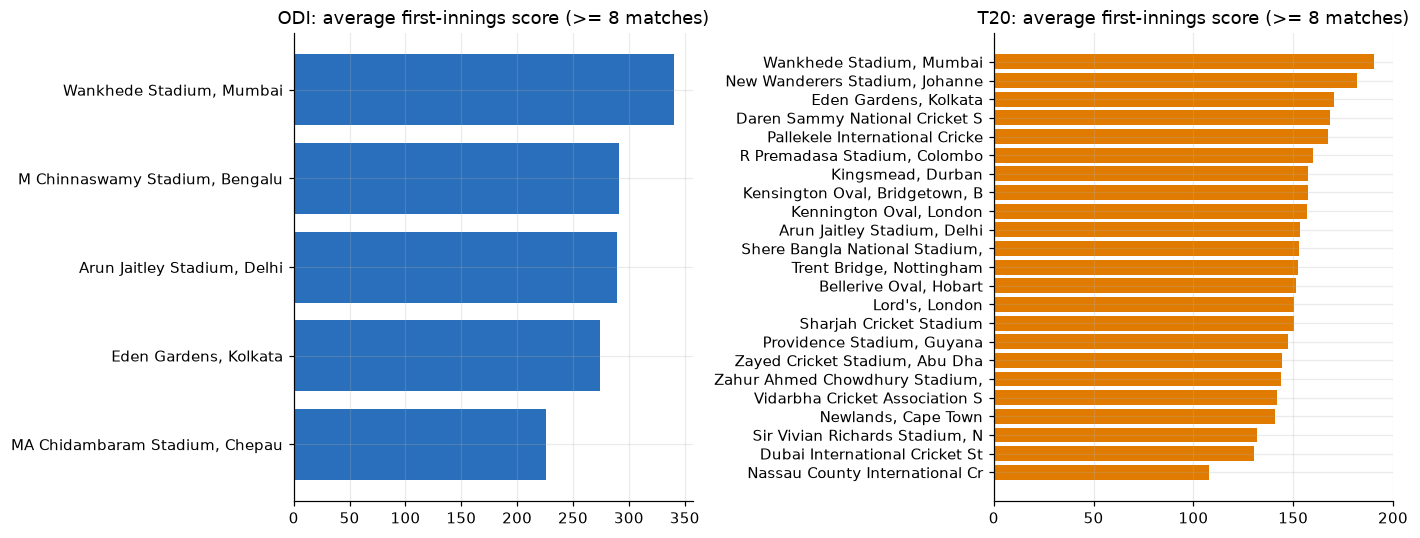

FINDING [ODI]: highest-scoring ground Wankhede Stadium, Mumbai (340); lowest MA Chidambaram Stadium, Chepauk, Chennai (226); spread 114 runs
FINDING [T20]: highest-scoring ground Wankhede Stadium, Mumbai (190); lowest Nassau County International Cricket Stadium, New York (108); spread 83 runs


In [4]:
v = q("select venue_name, city, format, matches, avg_first_innings_runs, bat_first_win_pct from dbt_analytics.an_venue_profile where matches >= 8 order by format, avg_first_innings_runs desc")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, f in zip(axes, ["ODI", "T20"]):
    g = v[v.format == f].sort_values("avg_first_innings_runs")
    ax.barh(g.venue_name.str.slice(0, 30), g.avg_first_innings_runs, color=FMT[f]); ax.set_title(f"{f}: average first-innings score (>= 8 matches)")
plt.tight_layout(); plt.show()
for f, g in v.groupby("format"):
    hi, lo = g.iloc[0], g.iloc[-1]
    print(f"FINDING [{f}]: highest-scoring ground {hi.venue_name} ({hi.avg_first_innings_runs:.0f}); lowest {lo.venue_name} ({lo.avg_first_innings_runs:.0f}); spread {hi.avg_first_innings_runs-lo.avg_first_innings_runs:.0f} runs")

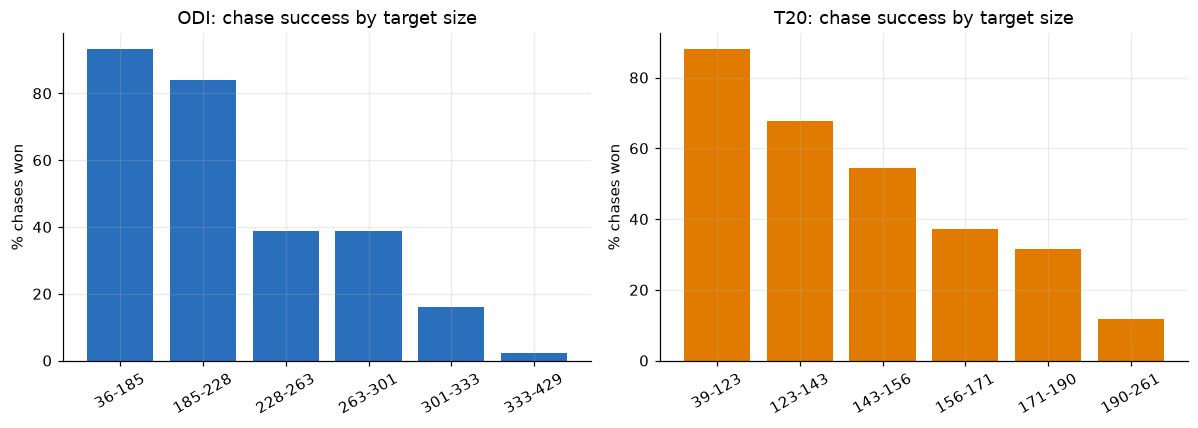

In [5]:
x = q("""select f.format, f.target, (f.winner_id = f.batting_second_team_id)::int chased from gold.fact_matches f
  where is_completed and not is_dls and not is_tie and winner_id is not null and target is not null""")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, f in zip(axes, ["ODI", "T20"]):
    g = x[x.format == f].copy(); g["bin"] = pd.qcut(g.target, 6, duplicates="drop")
    r = g.groupby("bin", observed=True).chased.agg(["mean", "count"])
    ax.bar(range(len(r)), 100 * r["mean"], color=FMT[f]); ax.set_xticks(range(len(r))); ax.set_xticklabels([f"{int(b.left)}-{int(b.right)}" for b in r.index], rotation=30)
    ax.set_title(f"{f}: chase success by target size"); ax.set_ylabel("% chases won")
plt.tight_layout(); plt.show()

## Data-quality caveat
Everything on this page that uses deliveries covers only matches with ball-by-ball data. Compare with notebook 01, which shows coverage by edition.

In [6]:
c = q("select sum(played_with_ball_by_ball) with_bbb, sum(played_matches) played from gold.mart_data_coverage")
print(f"Ball-by-ball based analysis covers {int(c.with_bbb[0])} of {int(c.played[0])} played matches.")

Ball-by-ball based analysis covers 488 of 652 played matches.
